# Airbnb Market Analysis

## Project Overview

This project analyzes Airbnb listings in New York City to understand pricing patterns, room-type distribution, customer engagement, availability, and host activity.

The analysis uses Python for data cleaning and exploratory data analysis, SQL for business-oriented analysis, and Power BI for interactive dashboard development.

## Business Objective

The objective is to identify meaningful patterns in the Airbnb market and provide data-driven insights that can help understand:

- Pricing differences across neighborhoods and boroughs
- Distribution and popularity of different room types
- Customer engagement through reviews
- Listing availability
- Host activity and listing concentration
- Geographic patterns in the Airbnb market

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SQL
- Power BI
- Jupyter Notebook

## Dataset

The project uses the **New York City Airbnb Open Data (2019)** dataset containing information about Airbnb listings, hosts, locations, room types, prices, reviews, minimum nights, and availability.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [57]:
# Load the Airbnb dataset

df = pd.read_csv("../data/airbnb_clean.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 48884
Columns: 16


In [4]:
# Check the dataset structure

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [5]:
# Display the first 5 rows of the dataset

df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
# Check missing values in each column

df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [7]:
# Check for duplicate rows

df.duplicated().sum()

np.int64(0)

In [8]:
# Check data types of all columns

df.dtypes

id                                  int64
name                                  str
host_id                             int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

In [9]:
# View basic statistics of numerical columns

df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [10]:
# Check unique values in important categorical columns

print("Neighbourhood Groups:")
print(df["neighbourhood_group"].unique())

print("\nRoom Types:")
print(df["room_type"].unique())

Neighbourhood Groups:
<StringArray>
['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
Length: 5, dtype: str

Room Types:
<StringArray>
['Private room', 'Entire home/apt', 'Shared room']
Length: 3, dtype: str


In [11]:
# Check for negative values in important numerical columns

print("Negative prices:", (df["price"] < 0).sum())
print("Negative minimum nights:", (df["minimum_nights"] < 0).sum())
print("Negative reviews:", (df["number_of_reviews"] < 0).sum())
print("Negative availability:", (df["availability_365"] < 0).sum())

Negative prices: 0
Negative minimum nights: 0
Negative reviews: 0
Negative availability: 0


In [12]:
# Create a working copy for data cleaning

df_clean = df.copy()

print("Working copy created successfully!")

Working copy created successfully!


In [13]:
# Handle missing values

# Listings without reviews have no monthly review activity
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)

# Replace missing listing and host names with a clear label
df_clean["name"] = df_clean["name"].fillna("Unknown")
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown")

# Keep missing last_review as missing because it represents
# listings that have no recorded review date
print("Missing values handled successfully!")

Missing values handled successfully!


In [14]:
# Convert last_review to datetime format

df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

print("last_review converted to datetime.")
print(df_clean["last_review"].dtype)

last_review converted to datetime.
datetime64[us]


In [15]:
# Check remaining missing values after cleaning

df_clean.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [16]:
# Check for duplicate listing IDs

df_clean["id"].duplicated().sum()

np.int64(0)

In [17]:
# Check listings with zero price

zero_price = (df_clean["price"] == 0).sum()

print("Listings with zero price:", zero_price)

Listings with zero price: 11


In [18]:
# Remove listings with zero price

df_clean = df_clean[df_clean["price"] > 0].copy()

print("Zero-price listings removed.")
print("Remaining rows:", len(df_clean))

Zero-price listings removed.
Remaining rows: 48884


In [19]:
# Verify the cleaned price data

print("Minimum price:", df_clean["price"].min())
print("Maximum price:", df_clean["price"].max())
print("Zero-price listings:", (df_clean["price"] == 0).sum())

Minimum price: 10
Maximum price: 10000
Zero-price listings: 0


In [20]:
# Find listings with very high prices

high_price = df_clean[df_clean["price"] >= 1000]

print("Listings priced at $1,000 or more:", len(high_price))

high_price[[
    "name",
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "price"
]].sort_values("price", ascending=False).head(20)

Listings priced at $1,000 or more: 298


,name,neighbourhood_group,neighbourhood,room_type,price
9151,Furnished room in Astoria apartment,Queens,Astoria,Private room,10000
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Greenpoint,Entire home/apt,10000
29238,1-BR Lincoln Center,Manhattan,Upper West Side,Entire home/apt,10000
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Lower East Side,Entire home/apt,9999
6530,Spanish Harlem Apt,Manhattan,East Harlem,Entire home/apt,9999
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Lower East Side,Private room,9999
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Tribeca,Entire home/apt,8500
4377,Film Location,Brooklyn,Clinton Hill,Entire home/apt,8000
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Upper East Side,Entire home/apt,7703
45666,Gem of east Flatbush,Brooklyn,East Flatbush,Private room,7500


In [21]:
# Check price distribution using percentiles

df_clean["price"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

0.25     69.0
0.50    106.0
0.75    175.0
0.90    269.0
0.95    355.0
0.99    799.0
Name: price, dtype: float64

In [22]:
# Check minimum-night distribution

df_clean["minimum_nights"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

0.25     1.0
0.50     3.0
0.75     5.0
0.90    28.0
0.95    30.0
0.99    45.0
Name: minimum_nights, dtype: float64

In [23]:
# Final check of the cleaned dataset

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Columns:", df_clean.shape[1])
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate IDs:", df_clean["id"].duplicated().sum())

Original rows: 48895
Cleaned rows: 48884
Rows removed: 11
Columns: 16
Missing values: 10051
Duplicate IDs: 0


In [24]:
# Analyze listing distribution by borough

borough_counts = df_clean["neighbourhood_group"].value_counts()

print(borough_counts)

neighbourhood_group
Manhattan        21660
Brooklyn         20095
Queens            5666
Bronx             1090
Staten Island      373
Name: count, dtype: int64


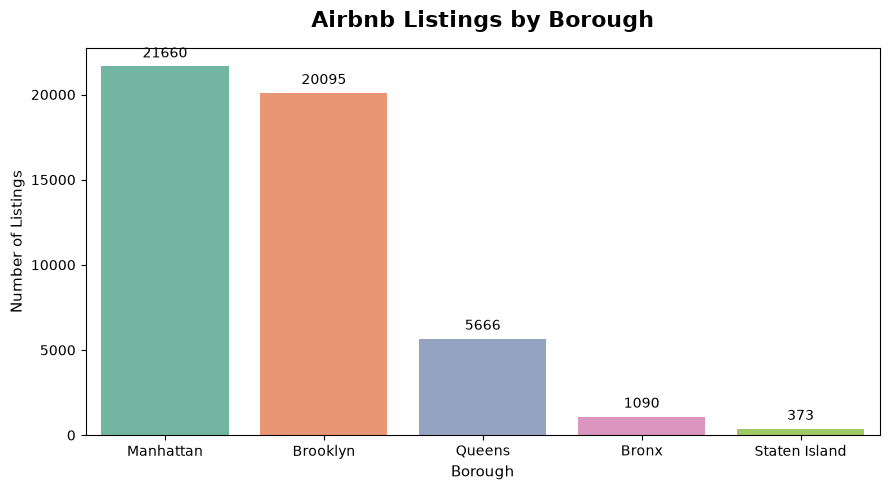

In [26]:
# Visualize Airbnb listings by borough

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=borough_counts.index,
    y=borough_counts.values,
    palette="Set2",
    hue=borough_counts.index,
    legend=False
)

plt.title("Airbnb Listings by Borough", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Borough", fontsize=11)
plt.ylabel("Number of Listings", fontsize=11)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=10)

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [27]:
# Analyze Airbnb listings by room type

room_type_counts = df_clean["room_type"].value_counts()

print(room_type_counts)

room_type
Entire home/apt    25407
Private room       22319
Shared room         1158
Name: count, dtype: int64


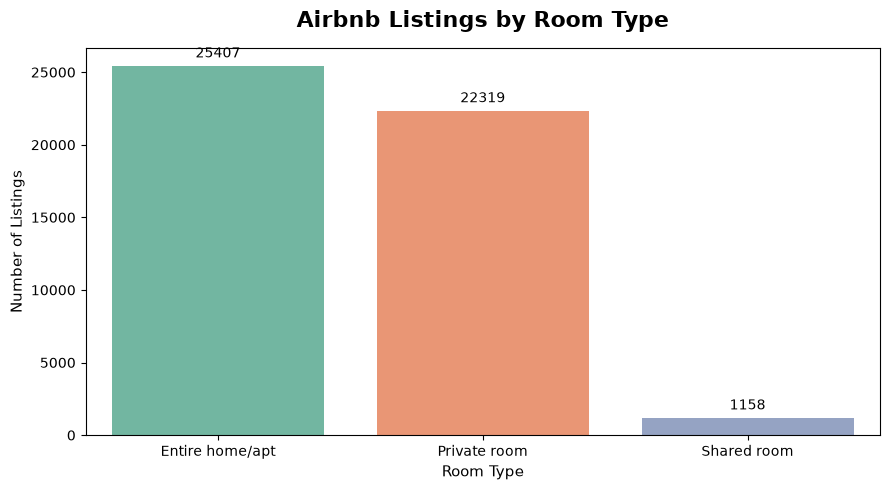

In [28]:
# Visualize Airbnb listings by room type

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=room_type_counts.index,
    y=room_type_counts.values,
    palette="Set2",
    hue=room_type_counts.index,
    legend=False
)

plt.title("Airbnb Listings by Room Type", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Room Type", fontsize=11)
plt.ylabel("Number of Listings", fontsize=11)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=10)

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [29]:
# Calculate average price by room type

avg_price_room = (
    df_clean.groupby("room_type")["price"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_price_room.round(2))

room_type
Entire home/apt    211.81
Private room        89.81
Shared room         70.25
Name: price, dtype: float64


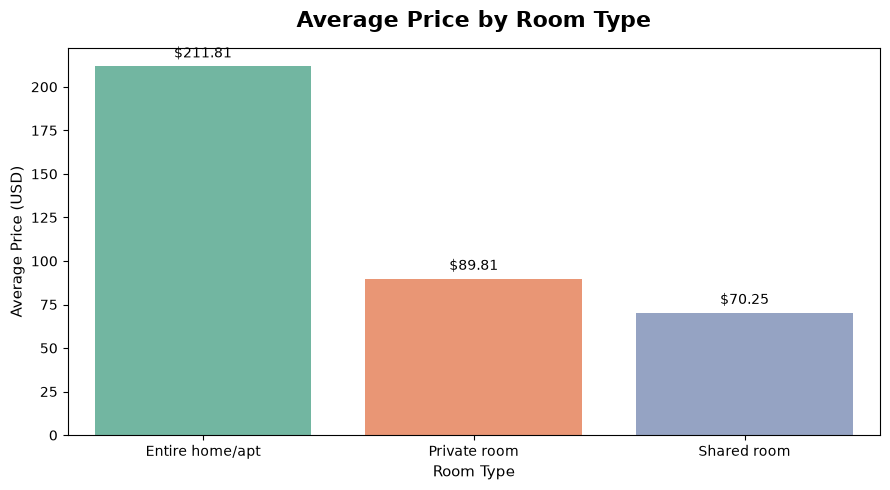

In [30]:
# Visualize average price by room type

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=avg_price_room.index,
    y=avg_price_room.values,
    palette="Set2",
    hue=avg_price_room.index,
    legend=False
)

plt.title("Average Price by Room Type", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Room Type", fontsize=11)
plt.ylabel("Average Price (USD)", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.2f",
        padding=4,
        fontsize=10
    )

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [31]:
# Calculate average price by borough

avg_price_borough = (
    df_clean.groupby("neighbourhood_group")["price"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_price_borough.round(2))

neighbourhood_group
Manhattan        196.88
Brooklyn         124.44
Staten Island    114.81
Queens            99.52
Bronx             87.58
Name: price, dtype: float64


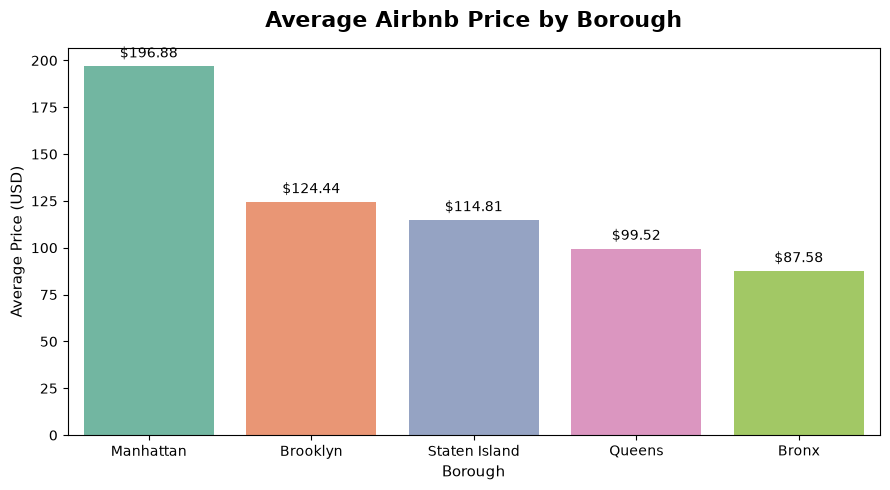

In [32]:
# Visualize average Airbnb price by borough

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=avg_price_borough.index,
    y=avg_price_borough.values,
    palette="Set2",
    hue=avg_price_borough.index,
    legend=False
)

plt.title(
    "Average Airbnb Price by Borough",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Borough", fontsize=11)
plt.ylabel("Average Price (USD)", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.2f",
        padding=4,
        fontsize=10
    )

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [33]:
# Find the top 10 neighbourhoods by number of listings

neighbourhood_counts = (
    df_clean["neighbourhood"]
    .value_counts()
    .head(10)
)

print(neighbourhood_counts)

neighbourhood
Williamsburg          3919
Bedford-Stuyvesant    3710
Harlem                2658
Bushwick              2462
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64


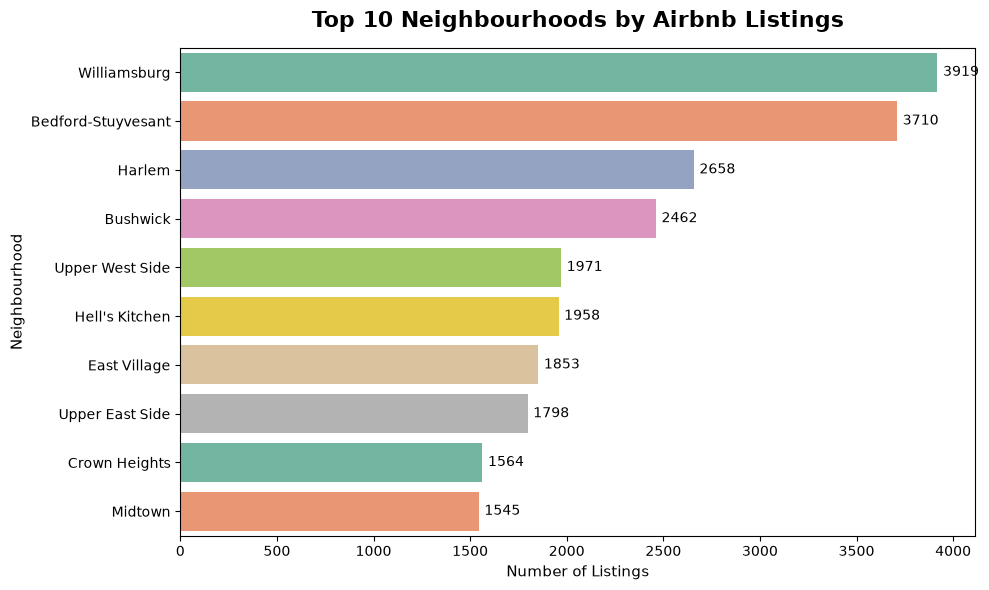

In [34]:
# Visualize the top 10 neighbourhoods by listing count

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=neighbourhood_counts.values,
    y=neighbourhood_counts.index,
    palette="Set2",
    hue=neighbourhood_counts.index,
    legend=False
)

plt.title(
    "Top 10 Neighbourhoods by Airbnb Listings",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Number of Listings", fontsize=11)
plt.ylabel("Neighbourhood", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4,
        fontsize=10
    )

plt.tight_layout()

plt.show()

In [35]:
# Calculate average price for neighbourhoods with at least 100 listings

neighbourhood_price = (
    df_clean.groupby("neighbourhood")
    .agg(
        average_price=("price", "mean"),
        listing_count=("id", "count")
    )
    .query("listing_count >= 100")
    .sort_values("average_price", ascending=False)
)

print(neighbourhood_price.head(10).round(2))

                    average_price  listing_count
neighbourhood                                   
Tribeca                    490.64            177
SoHo                       287.10            358
Midtown                    282.72           1545
West Village               267.68            768
Greenwich Village          263.41            392
Chelsea                    249.74           1113
Theater District           248.01            288
Nolita                     230.14            253
Financial District         225.49            744
Gramercy                   222.75            338


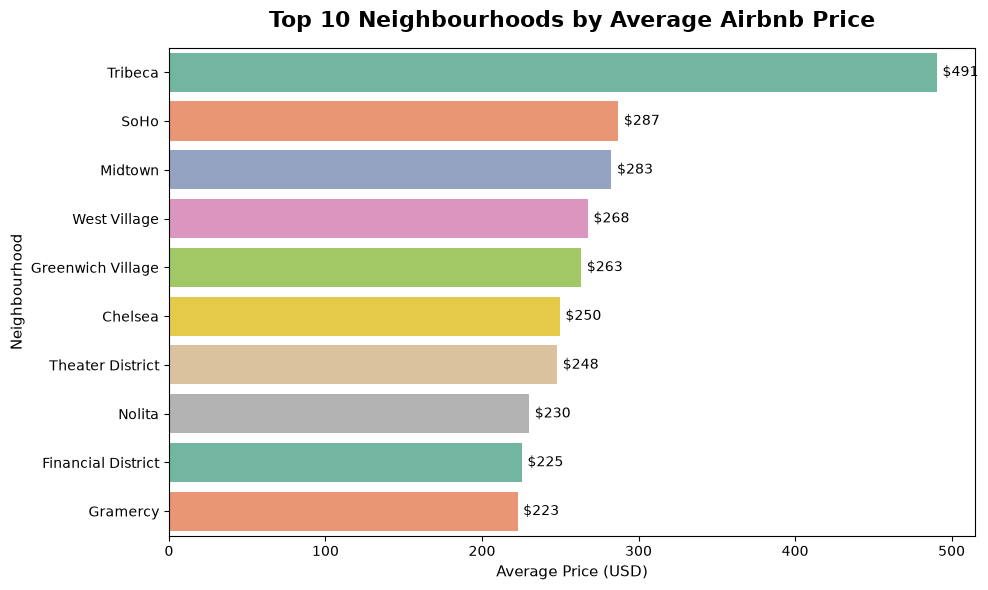

In [36]:
# Visualize the top 10 highest-priced neighbourhoods

top_price_neighbourhoods = neighbourhood_price.head(10)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_price_neighbourhoods["average_price"],
    y=top_price_neighbourhoods.index,
    palette="Set2",
    hue=top_price_neighbourhoods.index,
    legend=False
)

plt.title(
    "Top 10 Neighbourhoods by Average Airbnb Price",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Average Price (USD)", fontsize=11)
plt.ylabel("Neighbourhood", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=4,
        fontsize=10
    )

plt.tight_layout()

plt.show()

In [38]:
# Calculate review activity by room type

reviews_by_room = (
    df_clean.groupby("room_type")
    .agg(
        total_reviews=("number_of_reviews", "sum"),
        average_reviews=("number_of_reviews", "mean"),
        average_reviews_per_month=("reviews_per_month", "mean")
    )
    .sort_values("total_reviews", ascending=False)
)

print(reviews_by_room.round(2))

                 total_reviews  average_reviews  average_reviews_per_month
room_type                                                                 
Entire home/apt         580400            22.84                       1.05
Private room            537979            24.10                       1.14
Shared room              19249            16.62                       1.07


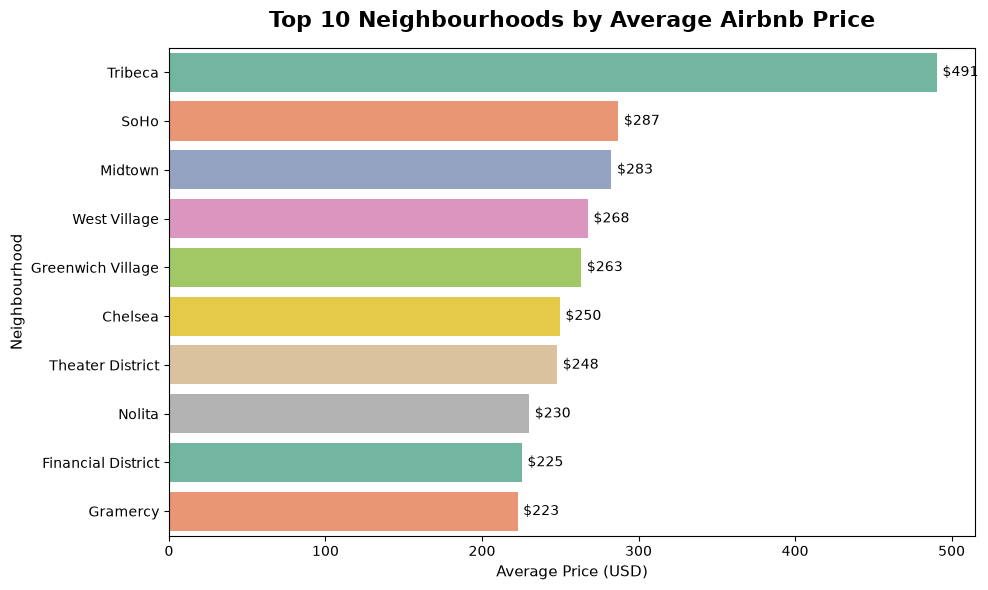

In [39]:
# Visualize the top 10 highest-priced neighbourhoods

top_price_neighbourhoods = neighbourhood_price.head(10)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_price_neighbourhoods["average_price"],
    y=top_price_neighbourhoods.index,
    palette="Set2",
    hue=top_price_neighbourhoods.index,
    legend=False
)

plt.title(
    "Top 10 Neighbourhoods by Average Airbnb Price",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Average Price (USD)", fontsize=11)
plt.ylabel("Neighbourhood", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [40]:
# Calculate average reviews by borough

avg_reviews_borough = (
    df_clean.groupby("neighbourhood_group")["number_of_reviews"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_reviews_borough.round(2))

neighbourhood_group
Staten Island    30.94
Queens           27.70
Bronx            25.98
Brooklyn         24.20
Manhattan        20.99
Name: number_of_reviews, dtype: float64


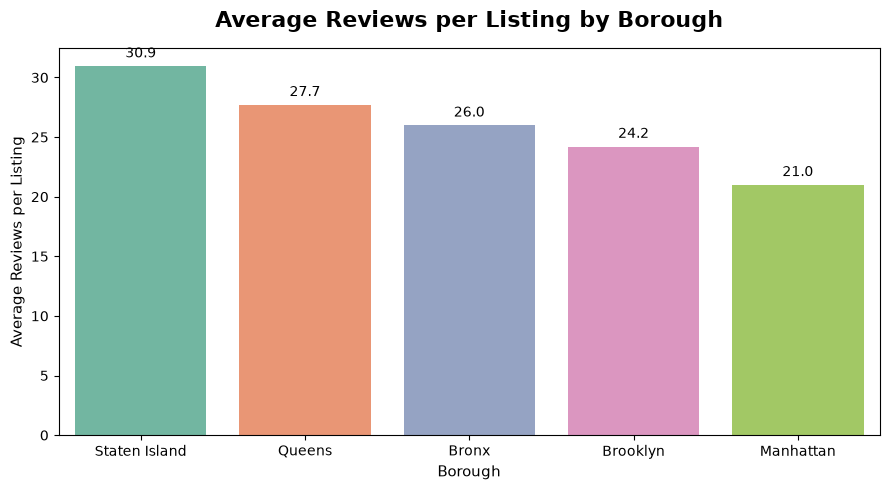

In [41]:
# Visualize average reviews by borough

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=avg_reviews_borough.index,
    y=avg_reviews_borough.values,
    palette="Set2",
    hue=avg_reviews_borough.index,
    legend=False
)

plt.title(
    "Average Reviews per Listing by Borough",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Borough", fontsize=11)
plt.ylabel("Average Reviews per Listing", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=4,
        fontsize=10
    )

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [42]:
# Calculate average monthly reviews by borough

monthly_reviews_borough = (
    df_clean.groupby("neighbourhood_group")["reviews_per_month"]
    .mean()
    .sort_values(ascending=False)
)

print(monthly_reviews_borough.round(2))

neighbourhood_group
Staten Island    1.58
Queens           1.57
Bronx            1.47
Brooklyn         1.05
Manhattan        0.98
Name: reviews_per_month, dtype: float64


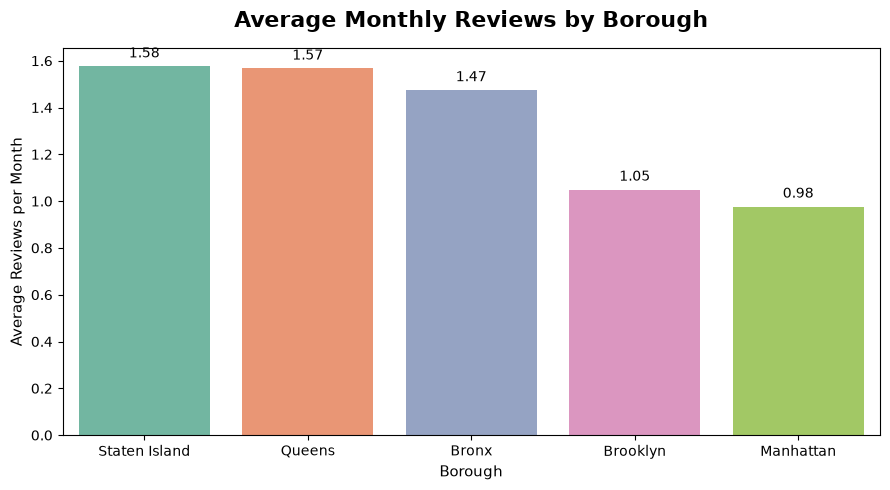

In [43]:
# Visualize average monthly review activity by borough

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=monthly_reviews_borough.index,
    y=monthly_reviews_borough.values,
    palette="Set2",
    hue=monthly_reviews_borough.index,
    legend=False
)

plt.title(
    "Average Monthly Reviews by Borough",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Borough", fontsize=11)
plt.ylabel("Average Reviews per Month", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [44]:
# Calculate average availability by room type

avg_availability_room = (
    df_clean.groupby("room_type")["availability_365"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_availability_room.round(2))

room_type
Shared room        161.87
Entire home/apt    111.93
Private room       111.20
Name: availability_365, dtype: float64


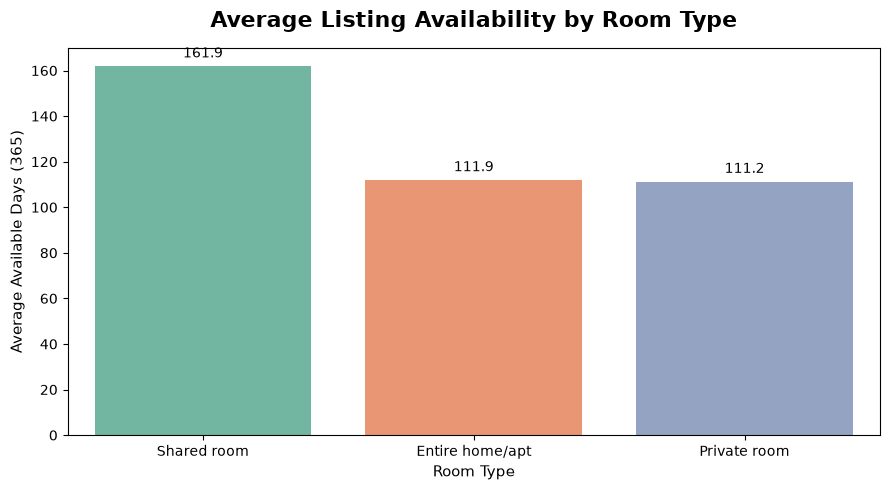

In [45]:
# Visualize average availability by room type

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=avg_availability_room.index,
    y=avg_availability_room.values,
    palette="Set2",
    hue=avg_availability_room.index,
    legend=False
)

plt.title(
    "Average Listing Availability by Room Type",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Room Type", fontsize=11)
plt.ylabel("Average Available Days (365)", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=4,
        fontsize=10
    )

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [46]:
# Find the top 10 hosts by number of listings

top_hosts = (
    df_clean.groupby(["host_id", "host_name"])["id"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

print(top_hosts)

host_id    host_name        
219517861  Sonder (NYC)         327
107434423  Blueground           232
30283594   Kara                 121
137358866  Kazuya               103
16098958   Jeremy & Laura        96
12243051   Sonder                96
61391963   Corporate Housing     91
22541573   Ken                   87
200380610  Pranjal               65
7503643    Vida                  52
Name: id, dtype: int64


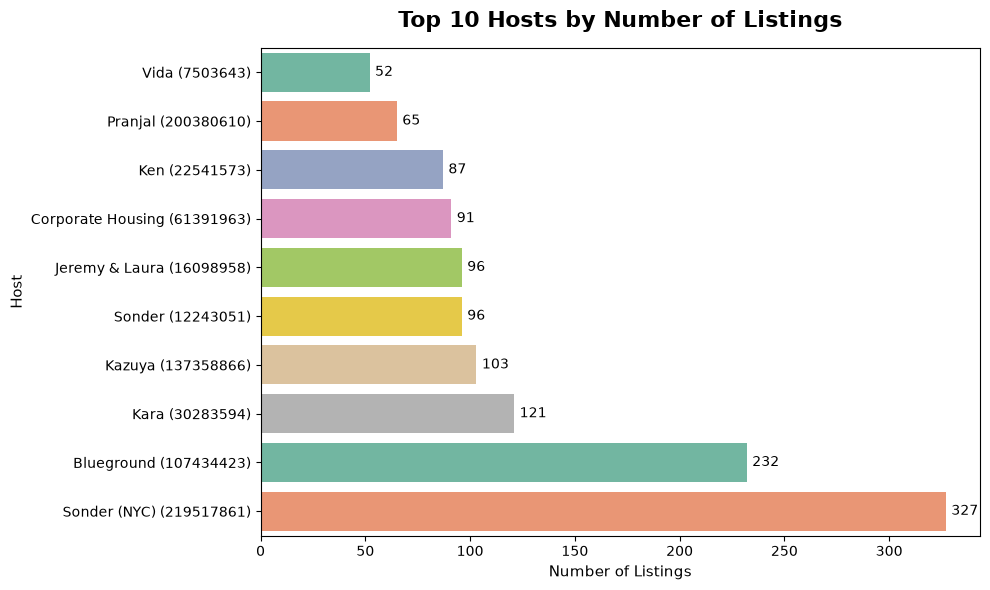

In [47]:
# Visualize the top 10 hosts by number of listings

top_hosts_plot = top_hosts.sort_values(ascending=True)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_hosts_plot.values,
    y=[f"{name} ({host_id})" for host_id, name in top_hosts_plot.index],
    palette="Set2",
    hue=[f"{name} ({host_id})" for host_id, name in top_hosts_plot.index],
    legend=False
)

plt.title(
    "Top 10 Hosts by Number of Listings",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Number of Listings", fontsize=11)
plt.ylabel("Host", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [48]:
# Analyze the relationship between price and number of reviews

price_reviews = df_clean[["price", "number_of_reviews"]].copy()

print(price_reviews.describe().round(2))

          price  number_of_reviews
count  48884.00           48884.00
mean     152.76              23.27
std      240.17              44.55
min       10.00               0.00
25%       69.00               1.00
50%      106.00               5.00
75%      175.00              24.00
max    10000.00             629.00


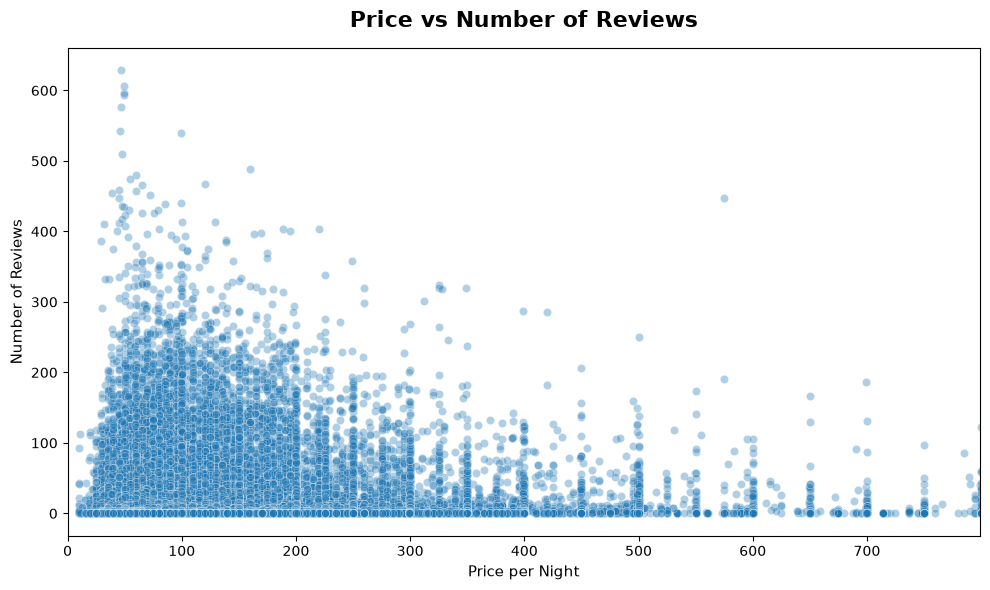

In [49]:
# Visualize the relationship between listing price and number of reviews

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="price",
    y="number_of_reviews",
    alpha=0.35,
    s=35
)

plt.title(
    "Price vs Number of Reviews",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Price per Night", fontsize=11)
plt.ylabel("Number of Reviews", fontsize=11)

plt.xlim(0, df_clean["price"].quantile(0.99))

plt.tight_layout()
plt.show()

In [50]:
# Calculate average listing availability by borough

availability_borough = (
    df_clean.groupby("neighbourhood_group")["availability_365"]
    .mean()
    .sort_values(ascending=False)
)

print(availability_borough.round(2))

neighbourhood_group
Staten Island    199.68
Bronx            165.79
Queens           144.45
Manhattan        111.98
Brooklyn         100.22
Name: availability_365, dtype: float64


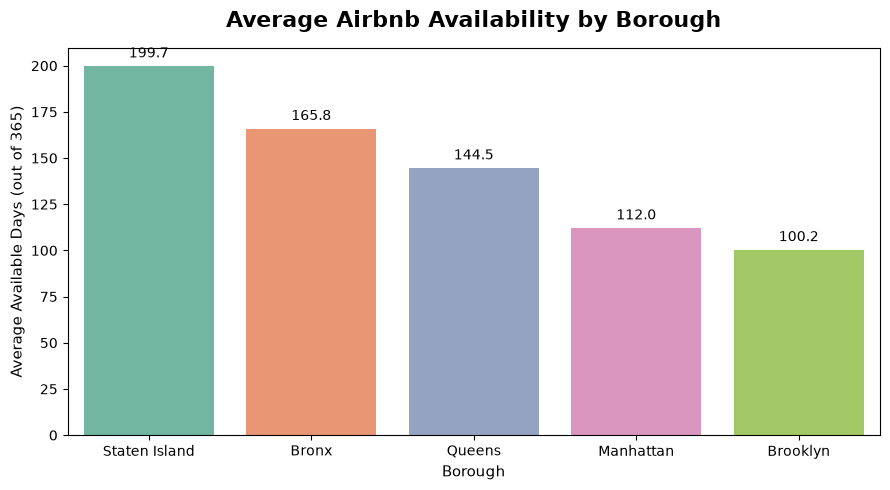

In [51]:
# Visualize average listing availability by borough

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=availability_borough.index,
    y=availability_borough.values,
    palette="Set2",
    hue=availability_borough.index,
    legend=False
)

plt.title(
    "Average Airbnb Availability by Borough",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Borough", fontsize=11)
plt.ylabel("Average Available Days (out of 365)", fontsize=11)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [52]:
# Calculate the share of listings managed by the top 10 hosts

total_listings = len(df_clean)
top_10_host_listings = top_hosts.sum()

top_10_share = (top_10_host_listings / total_listings) * 100

print("Total listings:", total_listings)
print("Listings managed by top 10 hosts:", top_10_host_listings)
print("Top 10 hosts' share of listings:", round(top_10_share, 2), "%")

Total listings: 48884
Listings managed by top 10 hosts: 1270
Top 10 hosts' share of listings: 2.6 %


In [53]:
# Analyze average price by borough and room type

price_borough_room = (
    df_clean
    .groupby(["neighbourhood_group", "room_type"])["price"]
    .mean()
    .round(2)
    .unstack()
)

print(price_borough_room)

room_type            Entire home/apt  Private room  Shared room
neighbourhood_group                                            
Bronx                         127.51         66.89        59.80
Brooklyn                      178.35         76.55        50.77
Manhattan                     249.26        116.78        88.98
Queens                        147.05         71.76        69.02
Staten Island                 173.85         62.29        57.44


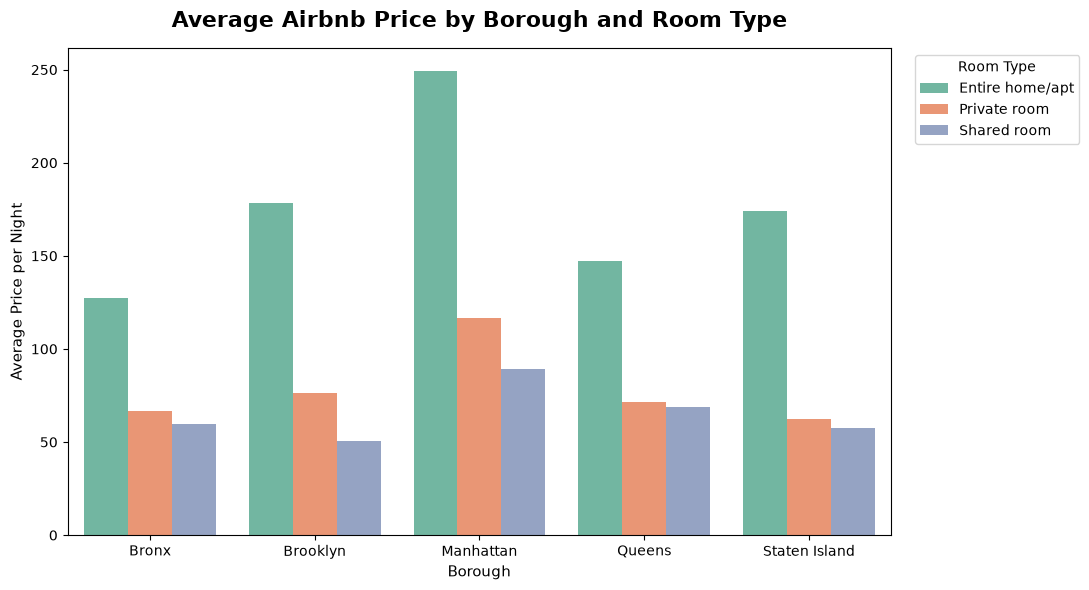

In [54]:
# Visualize average price by borough and room type

price_borough_room_plot = price_borough_room.reset_index().melt(
    id_vars="neighbourhood_group",
    var_name="room_type",
    value_name="average_price"
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=price_borough_room_plot,
    x="neighbourhood_group",
    y="average_price",
    hue="room_type",
    palette="Set2"
)

plt.title(
    "Average Airbnb Price by Borough and Room Type",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Borough", fontsize=11)
plt.ylabel("Average Price per Night", fontsize=11)

plt.legend(
    title="Room Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## Key EDA Findings

- Manhattan and Brooklyn contain the largest number of Airbnb listings in the dataset.
- Entire home/apt listings are the most common room type and have the highest average price.
- Manhattan has the highest average listing price among the five boroughs.
- Tribeca has the highest average price among neighbourhoods with at least 100 listings.
- Queens and Staten Island show higher average review activity than Manhattan and Brooklyn.
- Staten Island has the highest average listing availability, while Brooklyn has the lowest.
- The top 10 hosts manage 1,270 listings, representing approximately 2.6% of all cleaned listings.
- Price and number of reviews show a highly dispersed relationship, indicating that price alone does not explain customer engagement.
- Across every borough, entire home/apt listings have a higher average price than private or shared rooms.

In [ ]:
# Export the cleaned dataset for SQL and Power BI

output_path = "../data/airbnb_clean.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset exported successfully!")
print("File:", output_path)
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Cleaned dataset exported successfully!
File: ../data/airbnb_clean.csv
Rows: 48884
Columns: 16
